# 10 · Could the Isle Royale wolves have died out? Stochastic simulation (Q7)

The discrete-time model from notebook 09, with two kinds of randomness added:

M_(t+1) = M_t · exp[ r(1 − M_t/K) − f_t·W_t/M_t + ε_t ],  ε_t ~ N(0, σ_M²)

W_(t+1) ~ Poisson( W_t · exp[ e·f_t − d + η_t ] ),  η_t ~ N(0, σ_W²)

- ε, η = **environmental noise** (good and bad years for everyone).
- The Poisson draw = **demographic noise** (individual births and deaths), which matters most when there are few wolves.
- f_t = kill rate per wolf per year (prey-dependent form from notebook 09; the ratio-dependent form is a sensitivity check).

**σ_W without double counting.** The residuals of the fitted wolf equation already contain demographic noise.
For a Poisson count, the variance of log W_(t+1) given W_t is about 1/W_t, so the environmental part is
σ_W² = (residual variance) − mean(1/W_t), floored at a small positive value.

**Set-up (brief):** 10,000 runs from the 1990 counts, recording how often and how soon wolves fall to 2 or fewer.
The horizon is 26 years (1990 → 2016) so that the observed event (3 wolves in 2015, 2 in 2016) is inside it.

In [1]:
import sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import tsa_spec as spec

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "tables"; TAB.mkdir(parents=True, exist_ok=True)

# One colour per species in every figure (moose = blue, wolves = orange)
C_MOOSE, C_WOLF, C_3, C_4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SHADE = {"parvo_crash": "#d9d6cf", "near_extinction": "#e8e5df", "reintroduction": "#f0efec"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "figure.dpi": 110})

ir = pd.read_csv(ROOT / "data" / "processed" / "isle_royale_annual.csv", index_col="Year")
M_all, W_all = ir["Moose"].astype(float), ir["Wolves"].astype(float)
MAIN = list(range(1959, 2016))                      # main sample (brief): 1959-2015
M, W = M_all.loc[1959:2015], W_all.loc[1959:2015]
print("tsa_spec", spec.SPEC_VERSION, "| main sample", MAIN[0], "-", MAIN[-1], f"({len(MAIN)} years)")

import json
q6 = json.load(open(TAB / "IR_Q6_params.json"))
N_RUNS, START, END, THRESH = 10_000, 1990, 2016, 2
H = END - START
M0, W0 = M_all.loc[START], W_all.loc[START]
print(f"Start {START}: {M0:.0f} moose, {W0:.0f} wolves | horizon {H} years | {N_RUNS:,} runs")
print("Observed wolves:", W_all.loc[2010:2016].astype(int).to_dict())

tsa_spec 1.3 (2026-11-18) | main sample 1959 - 2015 (57 years)
Start 1990: 1315 moose, 15 wolves | horizon 26 years | 10,000 runs
Observed wolves: {2010: 19, 2011: 16, 2012: 9, 2013: 8, 2014: 9, 2015: 3, 2016: 2}


## 1. Parameters and noise levels

In [2]:
def noise_split(p):
    """Environmental wolf noise = total residual variance minus the Poisson part (mean 1/W over the fitting years)."""
    yrs = [int(y) for y in p["wolf_resid"].keys()]
    demog = float(np.mean(1 / W_all.loc[[y - 1 for y in yrs]].values))   # W_t that produced each W_(t+1)
    env = max(p["sigma_W_total"] ** 2 - demog, 0.01 ** 2)
    return np.sqrt(env), demog

pars = {}
for nm in ["prey-dependent", "ratio-dependent"]:
    p = dict(q6[nm]); p["sigma_W_env"], p["demog_var"] = noise_split(p)
    pars[nm] = p
ptab = pd.DataFrame({k: {kk: v for kk, v in p.items() if kk != "wolf_resid"} for k, p in pars.items()})
ptab.loc["share of wolf noise that is demographic"] = [p["demog_var"] / p["sigma_W_total"] ** 2 for p in pars.values()]
ptab.astype(float).round(4)

,prey-dependent,ratio-dependent
r,0.5110,0.6809
K,1717.2323,1900.5423
a,0.0297,NaN
h,0.0891,0.0500
sigma_M,0.1691,0.1670
e,0.0618,0.0210
d,0.5178,0.3039
sigma_W_total,0.2927,0.2927
sigma_W_env,0.1840,0.1839
demog_var,0.0519,0.0519


## 2. Simulation

In [3]:
def kill(m, w, p):
    if "a" in p:
        return p["a"] * m / (1 + p["a"] * p["h"] * m)
    R = np.where(w > 0, m / np.maximum(w, 1e-9), 0.0)
    return p["alpha"] * R / (1 + p["alpha"] * p["h"] * R)

def simulate(p, demographic=True, n=N_RUNS, h=H, seed=1):
    rng = np.random.default_rng(seed)
    Ms, Ws = np.empty((n, h + 1)), np.empty((n, h + 1))
    Ms[:, 0], Ws[:, 0] = M0, W0
    for t in range(h):
        m, w = Ms[:, t], Ws[:, t]
        f = np.where(w > 0, kill(m, w, p), 0.0)
        eps = rng.normal(0, p["sigma_M"], n)
        Ms[:, t + 1] = np.maximum(m * np.exp(p["r"] * (1 - m / p["K"]) - f * w / m + eps), 1.0)
        mean_w = w * np.exp(p["e"] * f - p["d"] + rng.normal(0, p["sigma_W_env"], n))
        Ws[:, t + 1] = rng.poisson(mean_w) if demographic else mean_w
    years = np.arange(START, END + 1)
    return pd.DataFrame(Ms, columns=years), pd.DataFrame(Ws, columns=years)

def summarise(Wd, label):
    hit = (Wd <= THRESH)
    first = hit.idxmax(axis=1).where(hit.any(axis=1))
    return {"run": label,
            f"P(wolves ≤ {THRESH} by {END})": hit.any(axis=1).mean(),
            f"P(wolves ≤ {THRESH} by 2015)": hit.loc[:, :2015].any(axis=1).mean(),
            "P(wolves = 0 by 2016)": (Wd <= 0).any(axis=1).mean(),
            "median first year ≤ 2 (runs that hit)": first.median(),
            "P(wolves ≤ 2 in 2016 itself)": (Wd[END] <= THRESH).mean(),
            "percentile of observed 2016 count (2)": 100 * (Wd[END] <= W_all.loc[END]).mean()}

runs, rows = {}, []
for nm in ["prey-dependent", "ratio-dependent"]:
    for demo in (True, False):
        lab = f"{nm}, {'environmental + demographic' if demo else 'environmental only'}"
        Md, Wd = simulate(pars[nm], demographic=demo)
        runs[lab] = (Md, Wd); rows.append(summarise(Wd, lab))
res = pd.DataFrame(rows).set_index("run")
res.round(3).to_csv(TAB / "IR_Q7_extinction_probability.csv")
res.round(3)

,P(wolves ≤ 2 by 2016),P(wolves ≤ 2 by 2015),P(wolves = 0 by 2016),median first year ≤ 2 (runs that hit),P(wolves ≤ 2 in 2016 itself),percentile of observed 2016 count (2)
run,,,,,,
"prey-dependent, environmental + demographic",0.516,0.494,0.363,2005.0,0.423,42.29
"prey-dependent, environmental only",0.031,0.027,0.000,2012.0,0.027,2.72
"ratio-dependent, environmental + demographic",0.336,0.325,0.210,2004.0,0.246,24.65
"ratio-dependent, environmental only",0.000,0.000,0.000,2009.0,0.000,0.00


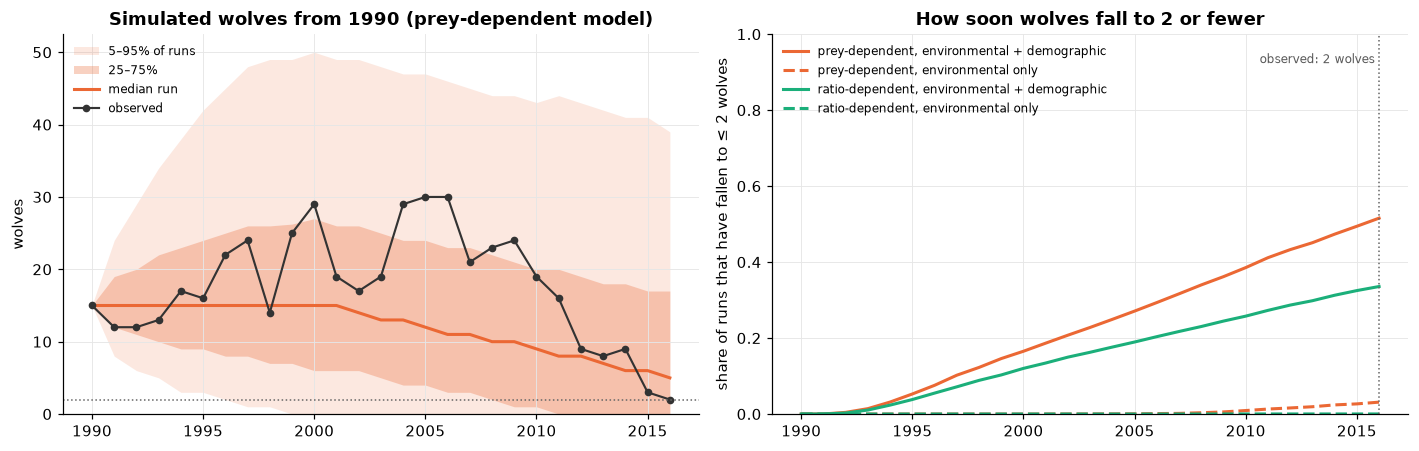

In [4]:
MAIN_RUN = "prey-dependent, environmental + demographic"
Md, Wd = runs[MAIN_RUN]
yrs = Wd.columns
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
q = Wd.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
ax.fill_between(yrs, q.loc[0.05], q.loc[0.95], color=C_WOLF, alpha=0.15, lw=0, label="5–95% of runs")
ax.fill_between(yrs, q.loc[0.25], q.loc[0.75], color=C_WOLF, alpha=0.3, lw=0, label="25–75%")
ax.plot(yrs, q.loc[0.5], color=C_WOLF, lw=2, label="median run")
ax.plot(W_all.loc[START:END].index, W_all.loc[START:END], "o-", color="0.2", ms=4, lw=1.4, label="observed")
ax.axhline(THRESH, color="0.4", ls=":", lw=1); ax.set_ylim(0, None)
ax.set_title(f"Simulated wolves from {START} (prey-dependent model)"); ax.set_ylabel("wolves"); ax.legend(frameon=False, fontsize=8)

ax = axes[1]
for lab, col, ls in [(MAIN_RUN, C_WOLF, "-"), ("prey-dependent, environmental only", C_WOLF, "--"),
                     ("ratio-dependent, environmental + demographic", C_3, "-"), ("ratio-dependent, environmental only", C_3, "--")]:
    W_ = runs[lab][1]
    cum = (W_ <= THRESH).cummax(axis=1).mean()
    ax.plot(cum.index, cum.values, ls, color=col, lw=2, label=lab)
ax.axvline(2016, color="0.4", ls=":", lw=1); ax.text(2015.8, 0.95, "observed: 2 wolves", ha="right", va="top", fontsize=8, color="0.35")
ax.set_ylim(0, 1); ax.set_ylabel(f"share of runs that have fallen to ≤ {THRESH} wolves")
ax.set_title("How soon wolves fall to 2 or fewer"); ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "IR_11_extinction_curves.png", dpi=200)

## 3. Is the result sensitive to the noise estimate?
The environmental wolf noise σ_W is the least certain input. Rerun the main model with σ_W halved and doubled.

In [5]:
rows = []
for mult in (0.5, 1.0, 2.0):
    p = dict(pars["prey-dependent"]); p["sigma_W_env"] *= mult
    for demo in (True, False):
        _, W_ = simulate(p, demographic=demo, seed=7)
        rows.append({"σ_W multiplier": mult, "demographic noise": demo,
                     f"P(≤ {THRESH} by {END})": (W_ <= THRESH).any(axis=1).mean()})
sens = pd.DataFrame(rows).pivot(index="σ_W multiplier", columns="demographic noise", values=f"P(≤ {THRESH} by {END})")
sens.columns = ["environmental only", "environmental + demographic"]
sens["added by demographic noise"] = sens["environmental + demographic"] - sens["environmental only"]
sens.round(3).to_csv(TAB / "IR_Q7_sensitivity.csv"); sens.round(3)

,environmental only,environmental + demographic,added by demographic noise
σ_W multiplier,,,
0.5,0.000,0.422,0.422
1.0,0.031,0.517,0.486
2.0,0.374,0.735,0.362


## Caveats for the write-up
- The real collapse also involved **inbreeding depression** and the **loss of ice bridges** that once let new wolves
  arrive from the mainland; the model has neither, so it can only say how likely the decline was from food supply and
  chance alone.
- The wolf equation in notebook 09 is weak (wolf growth barely tracks the fitted kill rate), so simulated wolves behave
  close to a random walk with drift. Results lean on the noise estimates; see section 3.
- Parameters were fitted on 1960–2015, which includes the decline itself, so this is a consistency check, not an
  out-of-sample prediction.

## Summary (plain English)

1. **The collapse was likely, not a freak event.** Starting from the 1990 counts (1,315 moose, 15 wolves), wolves fell to 2 or fewer by 2016 in 52% of 10,000 simulated runs, and died out completely in 36%. The observed 2016 count of 2 wolves sits at the 42nd percentile of simulated 2016 counts, a typical outcome under this model.

2. **Chance in a small population drives it.** With demographic noise (chance individual births and deaths) switched off, the risk drops from 52% to 3%. With only 15–30 wolves and no way for new wolves to arrive, a few unlucky years can push the population to zero; about 60% of the wolves' year-to-year variation is this kind of noise.

3. **The result holds up.** Halving or doubling the environmental noise gives 42–74% with demographic noise included. The ratio-dependent kill-rate version gives 34%: lower, but still roughly a one-in-three chance.

4. **The real wolves held on longer than most runs.** In runs that fell to 2 or fewer, the median year was 2005; the real population stayed at 15–30 through 2010 and then collapsed quickly in 2011–2015.

5. **Caveats.** The model has no inbreeding and no new wolves arriving over ice bridges, both of which made the real collapse more likely. Parameters were fitted on 1960–2015, which includes the decline, so this is a consistency check, not a prediction made in advance. The wolf equation's link to food is weak (notebook 9), so the result is mostly about population size and chance.